# First Triton kernel

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shoaibphysics/custom-kernels/blob/main/notebooks/03_first_triton_kernel.ipynb)

How do we divide an array computation into work that a GPU can execute?

We implement vector addition using a custom Triton kernel.
Step by step, we learn how to select elements, load inputs,
perform arithmetic, and store results.

We use PyTorch to manage GPU tensors and provide a reference
implementation. We then check our kernel's correctness and
measure its execution time.

This notebook runs in a compatible NVIDIA GPU environment.

## 1. Checking the GPU environment

We use a Google Colab GPU runtime for this notebook.

Before creating tensors, we check that a CUDA GPU is available
and record the GPU model, memory, and software versions.

We define a variable called `device` that identifies the currently
selected GPU. Later, we will pass `device=device` when creating
PyTorch tensors so their data is allocated on that GPU.

The GPU is detected automatically; we do not hard-code its model
or index.

In [1]:
import torch
import triton

# This notebook requires a CUDA GPU.
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab and run this cell again.")

# Identify the active GPU and reuse this device throughout the notebook.
device = torch.device("cuda", torch.cuda.current_device())
gpu = torch.cuda.get_device_properties(device)

print("Device:", device)
print("GPU:", gpu.name)
print("Compute capability:", f"{gpu.major}.{gpu.minor}")
print(f"Total GPU memory: {gpu.total_memory / 2**30:.2f} GiB")
print("PyTorch version:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("Triton version:", triton.__version__)

Device: cuda:0
GPU: Tesla T4
Compute capability: 7.5
Total GPU memory: 14.56 GiB
PyTorch version: 2.11.0+cu130
PyTorch CUDA build: 13.0
Triton version: 3.6.0


## 2. GPU tensors and a reference result

A PyTorch tensor has a shape, a dtype, and a device.

We create a one-dimensional tensor containing ten float32 values.
Passing `device=device` places its data on the GPU selected
in Section 1.

Our inputs are:

- x: the values 0, 1, 2, ..., 9.
- y: ten values, each equal to 2.

We calculate:

$$
z_i = x_i + y_i.
$$

The expected result is therefore 2, 3, 4, ..., 11.

We preallocate an output tensor called `reference`, then use
`torch.add(x, y, out=reference)` to write the result into it.

PyTorch supplies the GPU implementation for this calculation.
Later, our own Triton kernel will need to produce the same result.

GPU operations can execute asynchronously. We explicitly wait
for completion before inspecting the output.

In [2]:
n_elements = 10

# Create the first input directly on our selected GPU.
x = torch.arange(n_elements, dtype=torch.float32, device=device)

# These tensors inherit x's shape, dtype, and device.
y = torch.full_like(x, 2.0)
reference = torch.empty_like(x)

# Calculate the reference result using PyTorch's GPU implementation.
torch.add(x, y, out=reference)

# Wait for GPU work to finish.
torch.cuda.synchronize(device)

print("x:", x)
print("y:", y)
print("Reference result:", reference)

print("Shape:", tuple(reference.shape))
print("Dtype:", reference.dtype)
print("Device:", reference.device)

x: tensor([0., 1., 2., 3., 4., 5., 6., 7., 8., 9.], device='cuda:0')
y: tensor([2., 2., 2., 2., 2., 2., 2., 2., 2., 2.], device='cuda:0')
Reference result: tensor([ 2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.], device='cuda:0')
Shape: (10,)
Dtype: torch.float32
Device: cuda:0


## 3. Dividing the array into programs

Instead of writing a Python loop over individual elements,
we will launch several instances of our Triton program.

Each program instance handles a block of elements.
Its program ID determines which block it handles.

For an array of 10 elements and a block size of 4:

| Program ID | Element indices assigned |
|---|---|
| 0 | 0, 1, 2, 3 |
| 1 | 4, 5, 6, 7 |
| 2 | 8, 9, 10, 11 |

The starting index of a program's block is:

$$
\text{block start} = \text{program ID} \times \text{block size}.
$$

We add the positions within the block to obtain its element offsets.
These offsets count elements, not bytes.

Our array has valid indices 0 through 9. The final program therefore
contains two invalid positions: 10 and 11.

A mask identifies which positions are valid:

$$
\text{mask} = \text{offset} < N.
$$

We will apply this mask to GPU memory loads and stores so invalid
positions are not accessed.

The block size describes the number of elements assigned to a
program. It is not the number of GPU threads.

The following cell traces the indexing in Python. In Section 4,
we will use the same logic inside our GPU kernel.

In [3]:
block_size = 4
n_programs = triton.cdiv(n_elements, block_size)

local_offsets = torch.arange(block_size)

print("Number of elements:", n_elements)
print("Elements per program:", block_size)
print("Number of programs:", n_programs)

for program_id in range(n_programs):
    block_start = program_id * block_size

    offsets = block_start + local_offsets
    mask = offsets < n_elements

    print(f"\nProgram {program_id}")
    print("Element offsets:", offsets)
    print("Mask:", mask)

Number of elements: 10
Elements per program: 4
Number of programs: 3

Program 0
Element offsets: tensor([0, 1, 2, 3])
Mask: tensor([True, True, True, True])

Program 1
Element offsets: tensor([4, 5, 6, 7])
Mask: tensor([True, True, True, True])

Program 2
Element offsets: tensor([ 8,  9, 10, 11])
Mask: tensor([ True,  True, False, False])


## 4. Writing and launching our vector-addition kernel

We begin with contiguous, one-dimensional float32 inputs.

A Triton kernel is a function decorated with `@triton.jit`.
Triton compiles this function for execution on the GPU.

Each program instance:

1. Gets its program ID using `tl.program_id`.
2. Constructs its element offsets using `tl.arange`.
3. Loads the valid input elements.
4. Adds the loaded values.
5. Stores the valid results.

The arguments `x_ptr`, `y_ptr`, and `z_ptr` identify the starting
locations of the tensor data in GPU memory. Adding offsets to
these pointers identifies the elements we want to access.

`BLOCK_SIZE` is marked with `tl.constexpr`, meaning its value is
known when Triton compiles the kernel.

For masked loads, `other=0.0` supplies zero at invalid positions.
The store mask prevents those positions from writing to memory.

We launch the kernel with a grid specifying the number of
program instances. For 10 elements and a block size of 4,
the grid contains 3 programs.

In [4]:
import triton.language as tl

@triton.jit
def add_kernel(x_ptr, y_ptr, z_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    # Each program determines which elements it handles.
    program_id = tl.program_id(axis=0)
    offsets = program_id * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements

    # Read values from GPU memory.
    x_values = tl.load(x_ptr + offsets, mask=mask, other=0.0)
    y_values = tl.load(y_ptr + offsets, mask=mask, other=0.0)

    # Perform the elementwise additions.
    z_values = x_values + y_values

    # Write results only at valid positions.
    tl.store(z_ptr + offsets, z_values, mask=mask)

block_size = 4
grid = (triton.cdiv(x.numel(), block_size),)

output_triton = torch.empty_like(x)

add_kernel[grid](x, y, output_triton, x.numel(),BLOCK_SIZE=block_size)

torch.cuda.synchronize(device)

print("Launch grid:", grid)
print("Triton result:", output_triton)
print("PyTorch reference:", reference)

Launch grid: (3,)
Triton result: tensor([ 2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.], device='cuda:0')
PyTorch reference: tensor([ 2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.], device='cuda:0')


## 5. Correctness and GPU benchmarking

We will compare our Triton kernel with PyTorch across different array sizes.

For each size, we first check that Triton produces the correct result.
We include 257 elements to test a partially filled final block when
`BLOCK_SIZE = 256`.

Both implementations use a preallocated output, so allocation happens
outside the timed operation. `triton.testing.do_bench` performs warmup
and repeated measurements using GPU events.

We report **effective bandwidth**:

$$
\text{Effective bandwidth}
=
\frac{3N \times \text{bytes per element}}{\text{execution time}}
$$

The factor of three represents two input reads and one output write.
For FP32, each element occupies 4 bytes, giving $12N$ bytes of logical
memory traffic.

The plot shows median bandwidth; **higher is better**. The shaded region
comes from the 5th and 95th timing percentiles and shows variability
across measurements.

These bandwidth estimates use our logical byte count. They do not
directly measure traffic to GPU memory.

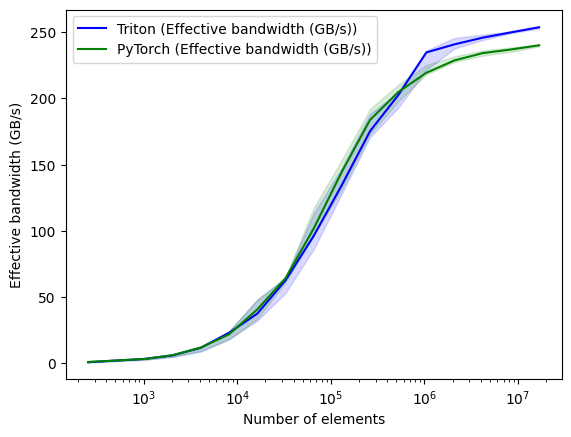

vector-add-performance:
          size  Triton (Effective bandwidth (GB/s))  PyTorch (Effective bandwidth (GB/s))
0        256.0                             0.494845                              0.482412
1        257.0                             0.504581                              0.703467
2       1024.0                             3.000000                              2.931298
3       2048.0                             5.731343                              5.818182
4       4096.0                            11.462686                             11.636364
5       8192.0                            22.755556                             21.633802
6      16384.0                            37.236364                             40.421054
7      32768.0                            62.375634                             63.999998
8      65536.0                            96.000000                            101.553721
9     131072.0                           134.478795                         

In [5]:
import triton.testing


@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=["size"],
        x_vals=[256, 257] + [2**i for i in range(10, 25)],
        x_log=True,
        line_arg="provider",
        line_vals=["triton", "torch"],
        line_names=["Triton", "PyTorch"],
        styles=[("blue", "-"), ("green", "-")],
        xlabel="Number of elements",
        ylabel="Effective bandwidth (GB/s)",
        plot_name="vector-add-performance",
        args={},
    )
)
def benchmark(size, provider):
    torch.manual_seed(0)
    x = torch.rand(size, device=device, dtype=torch.float32)
    y = torch.rand_like(x)
    output = torch.full_like(x, float("nan"))

    block_size = 256
    grid = (triton.cdiv(size, block_size),)

    def run_triton():
        add_kernel[grid](x, y, output, size, BLOCK_SIZE=block_size)

    # Check correctness before timing; this also compiles the kernel.
    run_triton()
    torch.testing.assert_close(output, x + y, rtol=0, atol=0)

    if provider == "triton":
        operation = run_triton
    else:
        operation = lambda: torch.add(x, y, out=output)

    median_ms, p05_ms, p95_ms = triton.testing.do_bench(operation, quantiles=[0.5, 0.05, 0.95])

    logical_bytes = 3 * size * x.element_size()

    def gbps(ms):
        return (logical_bytes * 1e-9) / (ms * 1e-3)

    # Longer time means lower bandwidth, so the bounds reverse.
    return gbps(median_ms), gbps(p95_ms), gbps(p05_ms)


benchmark.run(show_plots=True, print_data=True)
print("All tested sizes passed the correctness check.")

## 6. Final observations

We implemented vector addition using a custom Triton GPU kernel.

- Each program processes a block of elements.
- Offsets identify the elements that a program handles.
- Masks prevent invalid memory accesses in a partially filled block.
- We check correctness against PyTorch before benchmarking.
- We allocate outputs before timing and compare repeated measurements.

For small arrays, fixed overhead can dominate execution time, giving
low effective bandwidth. Larger arrays spread that overhead across
more work and can provide enough work to keep the GPU busy.

Eventually, memory bandwidth can become the main limit, so increasing
the array size does not keep increasing effective bandwidth.

For the same array size and dtype, both implementations have the same
logical byte count. Therefore, higher effective bandwidth corresponds
to shorter execution time.

### Observations from this run

Both implementations show increasing effective bandwidth as the arrays
grow, followed by a gradual flattening.

Their performance is similar at smaller and intermediate sizes, with
PyTorch slightly ahead at some intermediate sizes.

At the largest tested size, Triton reaches approximately 255 GB/s,
compared with approximately 240 GB/s for PyTorch. This corresponds to
about a $1.06\times$ speedup for Triton.

These values are estimated from the graph. The results apply to this
GPU, FP32 inputs, benchmark setup, and fixed Triton block size of 256.